# Closing prices prediction



In [1]:
# ===== Reproducibility =====
SEED = 2026
import torch
import random
import numpy as np

def set_seed(seed: int = 2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
# ===== Reproducibility =====

In [ ]:
# ===== Environment Setup & Required Packages =====
!pip install -q mplfinance

url = 'https://launchpad.net/~mario-mariomedina/+archive/ubuntu/talib/+files'
ext = '0.4.0-oneiric1_amd64.deb -qO'
!wget $url/libta-lib0_$ext libta.deb
!wget $url/ta-lib0-dev_$ext ta.deb
!dpkg -i libta.deb ta.deb
!pip install ta-lib==0.4.38

# ===== Environment Setup & Required Packages =====

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import mplfinance as mpf
import talib
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Part 1: Regression: Stock Price Prediction

In [5]:
df = pd.read_csv('AAPL.csv', parse_dates=['Date'])
df.head()

,Date,Close,High,Low,Open,Volume
0,2011-01-03,9.87,9.90,9.73,9.76,445138400
1,2011-01-04,9.93,9.96,9.83,9.96,309080800
2,2011-01-05,10.01,10.02,9.87,9.87,255519600
3,2011-01-06,10.00,10.05,9.97,10.03,300428800
4,2011-01-07,10.07,10.08,9.94,10.01,311931200


---
##  Data Visualization

In [6]:
close = df['Close'].values.astype(float)
high  = df['High'].values.astype(float)
low   = df['Low'].values.astype(float)

# Moving averages
df['MA10'] = talib.SMA(close, timeperiod=10)
df['MA30'] = talib.SMA(close, timeperiod=30)

# KD
df['K'], df['D'] = talib.STOCH(
    high, low, close,
    fastk_period=9,
    slowk_period=3, slowk_matype=0,
    slowd_period=3, slowd_matype=0
)

df[['Date','Close','MA10','MA30','K','D']].dropna().head()

,Date,Close,MA10,MA30,K,D
29,2011-02-14,10.76,10.531,10.269667,85.974026,87.674918
30,2011-02-15,10.78,10.575,10.300000,92.820513,88.336108
31,2011-02-16,10.88,10.631,10.331667,95.344551,91.379697
32,2011-02-17,10.74,10.676,10.356000,84.464712,90.876592
33,2011-02-18,10.50,10.688,10.372667,56.310866,78.706710


/usr/local/lib/python3.12/dist-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


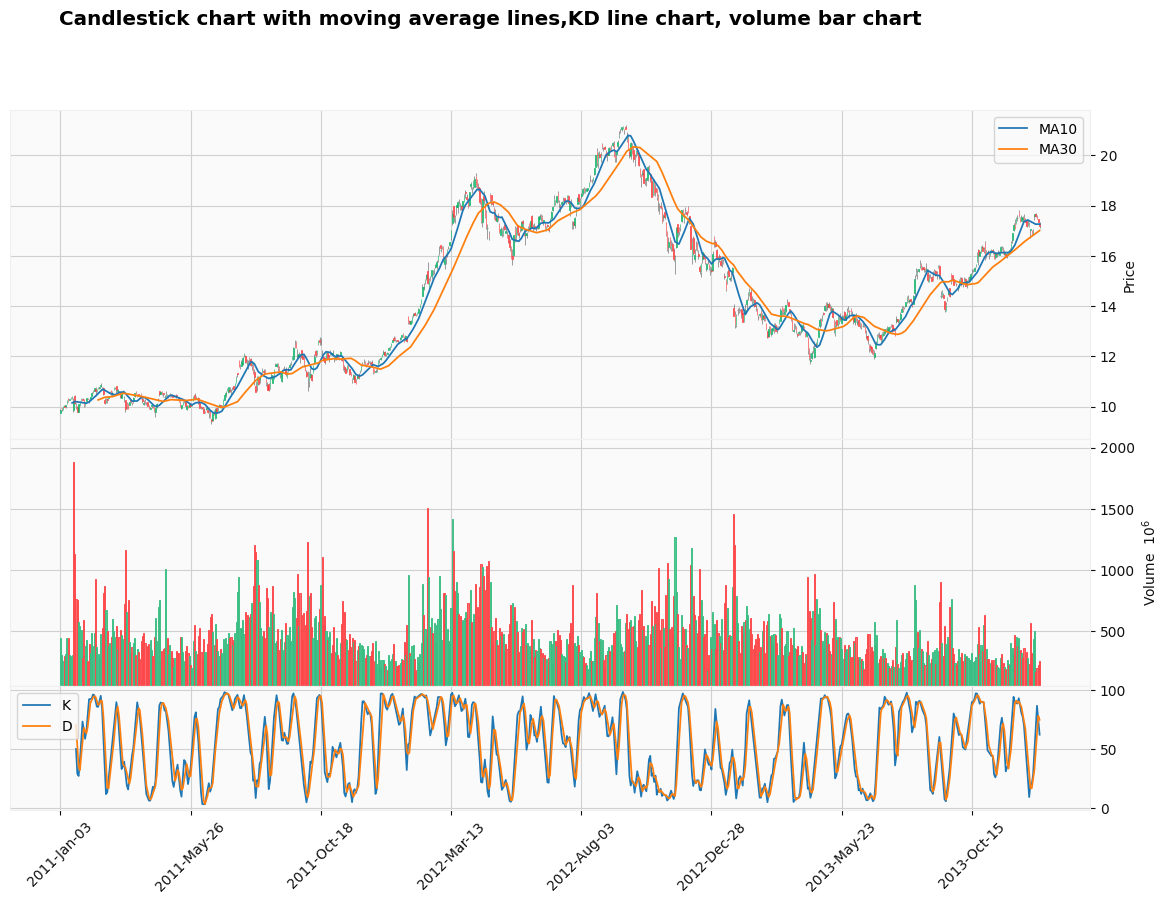

In [7]:
df_plot = df.copy()
df_plot['Date'] = pd.to_datetime(df['Date'])
df_plot.set_index('Date', inplace=True)

add_plots = [
    mpf.make_addplot(df_plot['MA10'],label='MA10',panel=0),
    mpf.make_addplot(df_plot['MA30'],label='MA30',panel=0),
    mpf.make_addplot(df_plot['K'] , panel=2, label='K'),
    mpf.make_addplot(df_plot['D'] , panel=2, label='D')
]


fig, axes = mpf.plot(
    df_plot,
    type='candle',
    volume=True,
    addplot=add_plots,
    style='yahoo',
    figsize=(15, 10),
    panel_ratios=(4, 3, 1.5),
    returnfig=True
)

fig.subplots_adjust(hspace=1.5)

fig.suptitle("Candlestick chart with moving average lines,KD line chart, volume bar chart")

plt.show()

---
##  Feature Engineering & Preprocessing

In [8]:
feature_cols = ['Open', 'High', 'Low', 'Close', 'Volume', 'MA10', 'MA30', 'K', 'D']
target_col   = 'Close'

df_feat = df[['Date'] + feature_cols].dropna().copy().reset_index(drop=True)

scaler = MinMaxScaler(feature_range=(0, 1))
df_feat[feature_cols] = scaler.fit_transform(df_feat[feature_cols])


close_idx = feature_cols.index('Close')
close_min  = scaler.data_min_[close_idx]
close_max  = scaler.data_max_[close_idx]

# For mse
def denormalize_close(x_norm):
    return x_norm * (close_max - close_min) + close_min

df_feat.head()

,Date,Open,High,Low,Close,Volume,MA10,MA30,K,D
0,2011-02-14,0.103004,0.106838,0.118298,0.112158,0.106727,0.071280,0.028799,0.867187,0.895868
1,2011-02-15,0.109013,0.108547,0.120000,0.113870,0.087123,0.075260,0.031721,0.939190,0.902912
2,2011-02-16,0.113305,0.120513,0.127660,0.122432,0.234283,0.080326,0.034771,0.965734,0.935334
3,2011-02-17,0.103863,0.108547,0.117447,0.110445,0.271207,0.084396,0.037114,0.851314,0.929974
4,2011-02-18,0.108155,0.106838,0.099574,0.089897,0.484476,0.085482,0.038720,0.555228,0.800334


---
##  Data Dimensions & Split

In [9]:
TIME_STEP   = 30
INPUT_DIM   = len(feature_cols)
BATCH_SIZE  = 32

print(f'Dimensions RNN : (batch={BATCH_SIZE}, time_steps={TIME_STEP}, input_dim={INPUT_DIM})')

train_mask = df_feat['Date'] <= '2012-12-31'
val_mask   = (df_feat['Date'] >= '2013-01-01') & (df_feat['Date'] <= '2013-06-30')
test_mask  = (df_feat['Date'] >= '2013-07-01') & (df_feat['Date'] <= '2013-12-30')

data_train = df_feat[train_mask][feature_cols].values
data_val   = df_feat[val_mask  ][feature_cols].values
data_test  = df_feat[test_mask ][feature_cols].values

Dimensions RNN : (batch=32, time_steps=30, input_dim=9)


In [ ]:
def make_sequences(data_prev, data_curr, time_step=30): # using 30 days to predict
    combined = np.concatenate([data_prev[-time_step:], data_curr], axis=0)
    X, y = [], []
    for i in range(len(data_curr)):
        X.append(combined[i : i + time_step])
        y.append(data_curr[i, feature_cols.index('Close')])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)



X_train, y_train = [], []
for i in range(TIME_STEP, len(data_train)): # start at index 30
    X_train.append(data_train[i - TIME_STEP : i])
    y_train.append(data_train[i, close_idx])
X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)


X_val,  y_val  = make_sequences(data_train, data_val)
X_test, y_test = make_sequences(data_val,   data_test)

print(f'X_train : {X_train.shape}  y_train : {y_train.shape}')
print(f'X_val   : {X_val.shape}    y_val   : {y_val.shape}')
print(f'X_test  : {X_test.shape}   y_test  : {y_test.shape}')

X_train : (443, 30, 9)  y_train : (443,)
X_val   : (124, 30, 9)    y_val   : (124,)
X_test  : (127, 30, 9)   y_test  : (127,)


In [11]:
class StockDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X)  # (N, 30, 9)
        self.y = torch.tensor(y)  # (N,)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_ds = StockDataset(X_train, y_train)
val_ds   = StockDataset(X_val,   y_val)
test_ds  = StockDataset(X_test,  y_test)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False)

---
## Training and evaluation functions

In [ ]:
def train_model(model, train_loader, val_loader, n_epochs=50, lr=1e-3):

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_losses, val_losses = [], []

    for epoch in range(1, n_epochs + 1):
        model.train()
        running_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            pred = model(X_batch).squeeze(-1)
            loss = criterion(pred, y_batch)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(X_batch)
        train_loss = running_loss / len(train_loader.dataset)


        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                pred = model(X_batch).squeeze(-1)
                val_loss += criterion(pred, y_batch).item() * len(X_batch)
        val_loss /= len(val_loader.dataset)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if epoch % 10 == 0:
            print(f'Epoch {epoch:}/{n_epochs} | Train MSE: {train_loss:} | Val MSE: {val_loss:}')

    return train_losses, val_losses



def evaluate_model(model, test_loader):
    model.eval()
    preds, targets = [], []
    
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(device)
            p = model(X_batch).squeeze(-1).cpu().numpy()
            preds.extend(p)
            targets.extend(y_batch.numpy())

    preds   = denormalize_close(np.array(preds))
    targets = denormalize_close(np.array(targets))
    mse  = np.mean((preds - targets) ** 2)
    rmse = np.sqrt(mse)
    return preds, targets, mse, rmse


def plot_results(train_losses, val_losses, preds, targets, mse, rmse, title):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Loss curve
    axes[0].plot(train_losses, label='Train loss')
    axes[0].plot(val_losses,   label='Val loss')
    axes[0].set_title(f'{title} — Loss Curve')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('MSE')
    axes[0].legend()


    # Predicition
    test_dates = df_feat[test_mask]['Date'].values[: len(preds)]
    axes[1].plot(test_dates, targets, label='Real Close')
    axes[1].plot(test_dates, preds,   label='Predicted Close',  linestyle='--')
    axes[1].set_title(f'{title} — Test Prediction\nMSE={mse:.6f}  RMSE={rmse:.6f}')
    axes[1].set_xlabel('Date')
    axes[1].set_ylabel('Close Price')
    axes[1].legend()


    plt.tight_layout()
    fname = f'fig_{title.lower().replace(" ", "_")}.png'

    plt.show()
    print(f'Test MSE  = {mse:.6f}')
    print(f'Test RMSE = {rmse:.6f}')
    return None


---
##  Vanilla RNN

In [ ]:
class VanillaRNN(nn.Module):
    def __init__(self, input_dim=9, hidden_dim=64, num_layers=2, output_dim=1):
        super(VanillaRNN, self).__init__()
        self.rnn = nn.RNN(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, _ = self.rnn(x)
        out = out[:, -1, :]         # just the final close prediction
        out = self.fc(out)
        return out


set_seed(SEED)
model_rnn = VanillaRNN(input_dim=INPUT_DIM, hidden_dim=64, num_layers=2).to(device)
print(model_rnn)

VanillaRNN(
  (rnn): RNN(9, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [31]:
set_seed(SEED)
train_losses_rnn, val_losses_rnn = train_model(
    model_rnn, train_loader, val_loader, n_epochs=50, lr=1e-3
)

Epoch 10/50 | Train MSE: 0.001595946970662737 | Val MSE: 0.0018355312847322034
Epoch 20/50 | Train MSE: 0.0014574489058005891 | Val MSE: 0.0009224943144457234
Epoch 30/50 | Train MSE: 0.0011944325333860604 | Val MSE: 0.0015796269402809202
Epoch 40/50 | Train MSE: 0.001131209118068891 | Val MSE: 0.0011089821768579104
Epoch 50/50 | Train MSE: 0.0011183580585480005 | Val MSE: 0.0008082846198381196


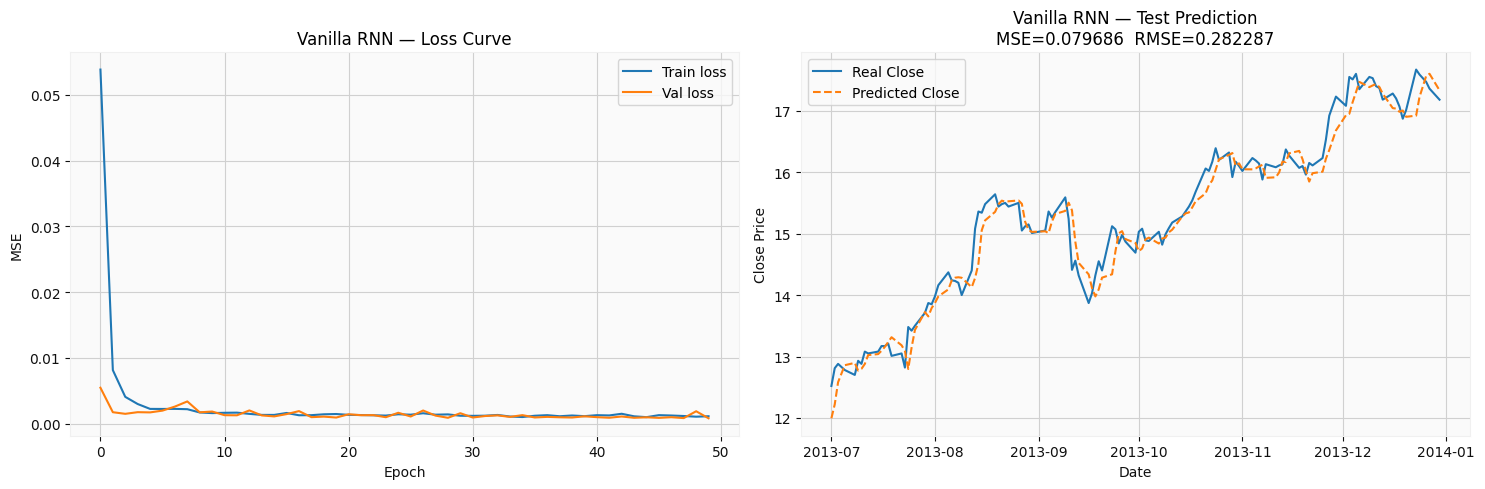

Test MSE  = 0.079686
Test RMSE = 0.282287


In [39]:
preds_rnn, targets_rnn, mse_rnn, rmse_rnn = evaluate_model(model_rnn, test_loader)

plot_results(train_losses_rnn, val_losses_rnn, preds_rnn, targets_rnn,
             mse_rnn, rmse_rnn, 'Vanilla RNN')

---
## LSTM

In [ ]:
class LSTMModel(nn.Module):
    def __init__(self, input_dim=9, hidden_dim=64, num_layers=2, output_dim=1):
        super(LSTMModel, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.fc(out)
        return out


set_seed(SEED)
model_lstm = LSTMModel(input_dim=INPUT_DIM, hidden_dim=64, num_layers=2).to(device)
print(model_lstm)

LSTMModel(
  (lstm): LSTM(9, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [41]:
set_seed(SEED)
train_losses_lstm, val_losses_lstm = train_model(
    model_lstm, train_loader, val_loader, n_epochs=50, lr=1e-3
)

Epoch 10/50 | Train MSE: 0.001979138576015662 | Val MSE: 0.0022216405862221316
Epoch 20/50 | Train MSE: 0.001810148795625157 | Val MSE: 0.001746736743840419
Epoch 30/50 | Train MSE: 0.001502140473498717 | Val MSE: 0.002009947846208008
Epoch 40/50 | Train MSE: 0.0013490788907687228 | Val MSE: 0.0015920990572926858
Epoch 50/50 | Train MSE: 0.0015442009182735168 | Val MSE: 0.0018864570170520774


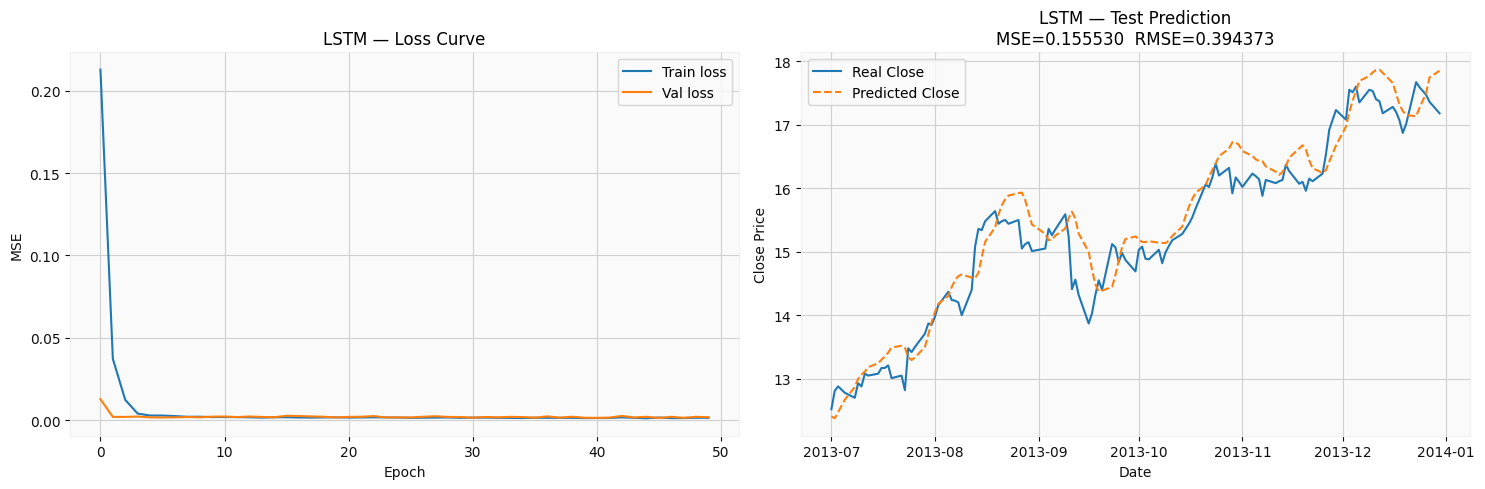

Test MSE  = 0.155530
Test RMSE = 0.394373


In [43]:
preds_lstm, targets_lstm, mse_lstm, rmse_lstm = evaluate_model(model_lstm, test_loader)
plot_results(train_losses_lstm, val_losses_lstm, preds_lstm, targets_lstm,
             mse_lstm, rmse_lstm, 'LSTM')

---
## GRU

In [ ]:
class GRUModel(nn.Module):
    def __init__(self, input_dim=9, hidden_dim=64, num_layers=2, output_dim=1):
        super(GRUModel, self).__init__()
        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out, _ = self.gru(x)
        out = out[:, -1, :]
        out = self.fc(out)
        return out


set_seed(SEED)
model_gru = GRUModel(input_dim=INPUT_DIM, hidden_dim=64, num_layers=2).to(device)
print(model_gru)

GRUModel(
  (gru): GRU(9, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [45]:
set_seed(SEED)
train_losses_gru, val_losses_gru = train_model(
    model_gru, train_loader, val_loader, n_epochs=50, lr=1e-3
)

Epoch 10/50 | Train MSE: 0.002003769405001173 | Val MSE: 0.0017071078801828047
Epoch 20/50 | Train MSE: 0.0014283230221298425 | Val MSE: 0.0013431648821419766
Epoch 30/50 | Train MSE: 0.0011799094807482735 | Val MSE: 0.0013343863763786371
Epoch 40/50 | Train MSE: 0.001007405654201389 | Val MSE: 0.001114282541112193
Epoch 50/50 | Train MSE: 0.0012607976592421263 | Val MSE: 0.0012125291658805744


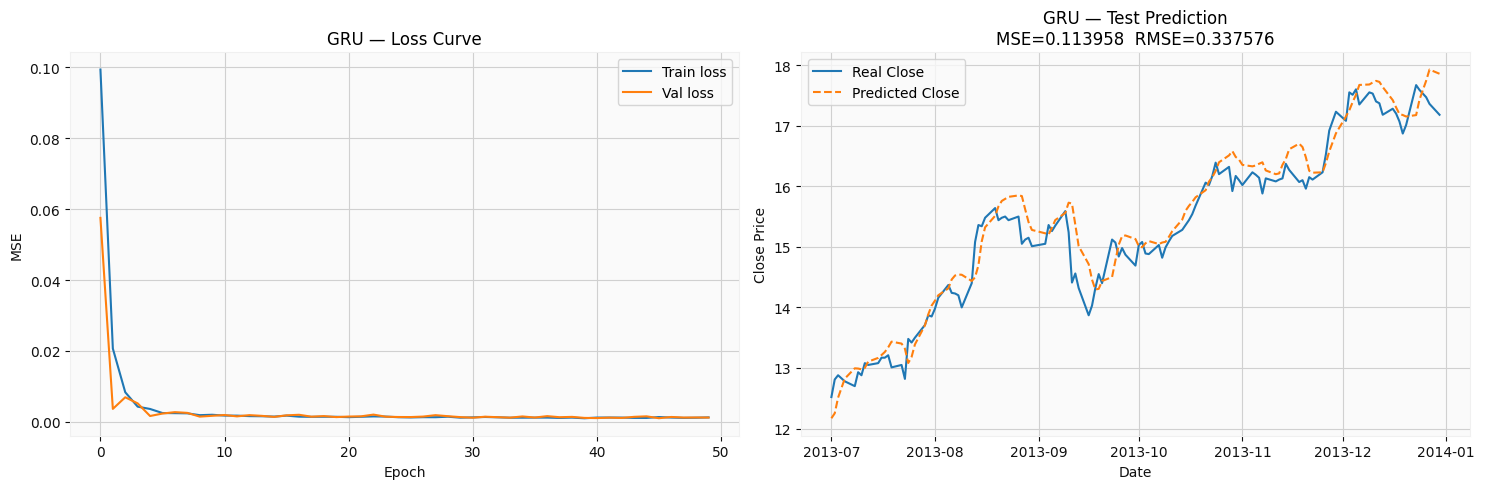

Test MSE  = 0.113958
Test RMSE = 0.337576


In [46]:
preds_gru, targets_gru, mse_gru, rmse_gru = evaluate_model(model_gru, test_loader)
plot_results(train_losses_gru, val_losses_gru, preds_gru, targets_gru,
             mse_gru, rmse_gru, 'GRU')

# Part 2 : Daily News for Stock Price Prediction

In [48]:
raw_news = pd.read_pickle(r'AAPL_news.pkl')

df_news = pd.DataFrame(raw_news)

print(f'News  : {df_news.shape}')

df_news.head(10)

News  : (5357, 4)


,0,1,2,3
0,"[C, AAPL, GOOG]",2011-02-14,pandora sales more than double ahead of ipo,pandora media inc the internet music company p...
1,"[GOOG, 6758, CMCSA, TWX, AAPL, LGF, NWSA, DIS]",2011-02-27,youtube said to plan movie rentals from sony u...,google inc goog s youtube video website plans ...
2,"[VSEA, PBH, ADBE, AAPL, FDO, GOOG, MAKO, MBI, ...",2011-03-01,amazoncom apple google nyse euronext us equity...,shares of the following companies may have unu...
3,"[AAPL, TWX, CBS, GM, HPQ]",2011-03-02,all ncaa basketball tournament games will be o...,every mens college basketball national champio...
4,"[TXN, AAPL, XLNX, ALTR, 9984, 4689, NE, MEE, M...",2011-03-02,us stocks advance on signs of strengthening la...,us stocks rose rebounding from yesterdays tumb...
5,"[AAPL, GOOG, HPQ, RIM, SIMG, ZAGG]",2011-03-02,apples jobs reappears to unveil ipad 2 as riva...,apple inc aapl chief executive officer steve j...
6,"[NWSA, AAPL]",2011-03-03,murdochs news corp may have to pay 174 billion...,rupert murdochs news corp nwsa may have to rai...
7,"[FTE, ILD, AAPL, VIV, EN]",2011-03-03,iliad wins 3g deal from france telecom opening...,france telecom sa fte will allow iliad sa ild ...
8,"[2308, AAPL, HPQ, 2448]",2011-03-03,delta electronics of taiwan considers acquisit...,delta electronics inc 2308 which has half of ...
9,[AAPL],2011-03-03,apple to reimburse recent ipad buyers after ne...,apple inc aapl which introduced the ipad 2 ye...


In [49]:
# Concatenate information

df_news[1] = pd.to_datetime(df_news[1])


df_news['text'] = df_news[2].fillna('') + ' ' + df_news[3].fillna('')
df_news['text'] = df_news['text'].str.strip()

news_by_date = df_news.groupby(1)['text'].apply(
    lambda texts: ' '.join(texts.tolist())
).reset_index()
news_by_date.columns = ['Date', 'daily_text']

news_by_date['Date']=pd.to_datetime(news_by_date['Date'])
news_by_date.head()

,Date,daily_text
0,2011-02-14,pandora sales more than double ahead of ipo pa...
1,2011-02-27,youtube said to plan movie rentals from sony u...
2,2011-03-01,amazoncom apple google nyse euronext us equity...
3,2011-03-02,all ncaa basketball tournament games will be o...
4,2011-03-03,murdochs news corp may have to pay 174 billion...


---

## BERT

In [50]:
from transformers import BertTokenizer, BertModel


BERT_MODEL = 'bert-base-uncased'
tokenizer  = BertTokenizer.from_pretrained(BERT_MODEL)
bert       = BertModel.from_pretrained(BERT_MODEL).to(device)
bert.eval()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False)
  

In [57]:
import os

EMBED_CACHE = 'bert_embeddings.pkl'

if os.path.exists(EMBED_CACHE):
    os.remove(EMBED_CACHE)

In [65]:
EMBED_CACHE = 'bert_embeddings.pkl'

if os.path.exists(EMBED_CACHE):
    with open(EMBED_CACHE, 'rb') as f:
        date_to_embedding = pickle.load(f)
else:
    date_to_embedding = {}

    for _, row in news_by_date.iterrows():
        text = row['daily_text']
        date = row['Date']

        inputs = tokenizer(
            text,
            return_tensors='pt',
            truncation=True,
            max_length=512,
            padding=True
        )
        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = bert(**inputs)
            cls_embedding = outputs.last_hidden_state[:, 0, :].squeeze(0).cpu().numpy()

        date_to_embedding[date] = cls_embedding

    with open(EMBED_CACHE, 'wb') as f:
        pickle.dump(date_to_embedding, f)

---

## Concatenating

In [74]:
BERT_DIM = 768
zero_embedding = np.zeros(BERT_DIM, dtype=np.float32)


embeddings_list = []
for date in df_feat['Date']:
    date_ts = pd.Timestamp(date)
    if date_ts in date_to_embedding:
        embeddings_list.append(date_to_embedding[date_ts].astype(np.float32))
    else:
        embeddings_list.append(zero_embedding)

embeddings_array = np.stack(embeddings_list)  # (N_days, 768)

n_with_news = sum(1 for e in embeddings_list if e.sum() != 0)

---

## Split

In [66]:
train_mask = df_feat['Date'] <= '2012-12-31'
val_mask   = (df_feat['Date'] >= '2013-01-01') & (df_feat['Date'] <= '2013-06-30')
test_mask  = (df_feat['Date'] >= '2013-07-01') & (df_feat['Date'] <= '2013-11-26')

num_train = df_feat[train_mask][feature_cols].values
num_val   = df_feat[val_mask  ][feature_cols].values
num_test  = df_feat[test_mask ][feature_cols].values

emb_train = embeddings_array[train_mask.values]
emb_val   = embeddings_array[val_mask.values]
emb_test  = embeddings_array[test_mask.values]

print(f'Train : {num_train.shape}, embeddings : {emb_train.shape}')
print(f'Val   : {num_val.shape},   embeddings : {emb_val.shape}')
print(f'Test  : {num_test.shape},  embeddings : {emb_test.shape}')

Train : (473, 9), embeddings : (473, 768)
Val   : (124, 9),   embeddings : (124, 768)
Test  : (105, 9),  embeddings : (105, 768)


In [ ]:
TIME_STEP = 30

def make_sequences_bert(num_prev, num_curr, emb_prev, emb_curr, time_step=30):

    num_combined = np.concatenate([num_prev[-time_step:], num_curr], axis=0)
    X_num, X_emb, y = [], [], []
    for i in range(len(num_curr)):
        X_num.append(num_combined[i : i + time_step])
        X_emb.append(emb_curr[i])
    return (np.array(X_num, dtype=np.float32),
            np.array(X_emb, dtype=np.float32),
            np.array(y,     dtype=np.float32))


Xn_train, Xe_train, y_train = [], [], []

for i in range(TIME_STEP, len(num_train)):
    Xn_train.append(num_train[i - TIME_STEP : i])
    Xe_train.append(emb_train[i])
    y_train.append(num_train[i, close_idx])
    
Xn_train = np.array(Xn_train, dtype=np.float32)
Xe_train = np.array(Xe_train, dtype=np.float32)
y_train  = np.array(y_train,  dtype=np.float32)


Xn_val, Xe_val, y_val   = make_sequences_bert(num_train, num_val,  emb_train, emb_val)
Xn_test, Xe_test, y_test = make_sequences_bert(num_val,  num_test, emb_val,   emb_test)


print(f'X_num_train : {Xn_train.shape}, X_emb_train : {Xe_train.shape}')
print(f'X_num_val   : {Xn_val.shape},   X_emb_val   : {Xe_val.shape}')
print(f'X_num_test  : {Xn_test.shape},  X_emb_test  : {Xe_test.shape}')

X_num_train : (443, 30, 9), X_emb_train : (443, 768)
X_num_val   : (124, 30, 9),   X_emb_val   : (124, 768)
X_num_test  : (105, 30, 9),  X_emb_test  : (105, 768)


In [ ]:
class StockBertDataset(Dataset):
    def __init__(self, X_num, X_emb, y):
        self.X_num = torch.tensor(X_num)  # (N, 30, 9)
        self.X_emb = torch.tensor(X_emb)  # (N, 768)
        self.y     = torch.tensor(y)      # (N,)
        
    def __len__(self):
        return len(self.y)
    
    def __getitem__(self, idx):
        return self.X_num[idx], self.X_emb[idx], self.y[idx]


BATCH_SIZE = 32
train_ds = StockBertDataset(Xn_train, Xe_train, y_train)
val_ds   = StockBertDataset(Xn_val,   Xe_val,   y_val)
test_ds  = StockBertDataset(Xn_test,  Xe_test,  y_test)


train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False)

---

## LSTM + BERT

In [95]:
class LSTMBertModel(nn.Module):
    def __init__(self, num_input_dim=9, hidden_dim=64, num_layers=2,
                 bert_dim=768, proj_dim=32):
        super(LSTMBertModel, self).__init__()

        self.lstm = nn.LSTM(
            input_size=num_input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )


        self.bert_proj = nn.Sequential(
            nn.Linear(bert_dim, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.Tanh(),
            nn.Dropout(0.2)
        )

        self.fc = nn.Linear(hidden_dim + proj_dim, 1)

    def forward(self, x_num, x_emb):
        lstm_out, _ = self.lstm(x_num)
        lstm_last   = lstm_out[:, -1, :]

        bert_out = self.bert_proj(x_emb)

        combined = torch.cat([lstm_last, bert_out], dim=-1)
        out = self.fc(combined)
        return out

set_seed(SEED)
model_bert = LSTMBertModel(
    num_input_dim=9, hidden_dim=64, num_layers=2,
    bert_dim=768, proj_dim=32
).to(device)
print(model_bert)

LSTMBertModel(
  (lstm): LSTM(9, 64, num_layers=2, batch_first=True, dropout=0.2)
  (bert_proj): Sequential(
    (0): Linear(in_features=768, out_features=32, bias=True)
    (1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    (2): Tanh()
    (3): Dropout(p=0.2, inplace=False)
  )
  (fc): Linear(in_features=96, out_features=1, bias=True)
)


In [ ]:
def train_bert_model(model, train_loader, val_loader, n_epochs=50, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_losses, val_losses = [], []

    for epoch in range(1, n_epochs + 1):
        model.train()
        running_loss = 0.0
        
        for X_num, X_emb, y_batch in train_loader:
            X_num, X_emb, y_batch = X_num.to(device), X_emb.to(device), y_batch.to(device)
            optimizer.zero_grad()
            pred = model(X_num, X_emb).squeeze(-1)
            loss = criterion(pred, y_batch)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(X_num)
        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_num, X_emb, y_batch in val_loader:
                X_num, X_emb, y_batch = X_num.to(device), X_emb.to(device), y_batch.to(device)
                pred = model(X_num, X_emb).squeeze(-1)
                val_loss += criterion(pred, y_batch).item() * len(X_num)
        val_loss /= len(val_loader.dataset)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if epoch % 10 == 0:
            print(f'Epoch {epoch:}/{n_epochs} | Train MSE: {train_loss:} | Val MSE: {val_loss:}')

    return train_losses, val_losses


set_seed(SEED)
train_losses_bert, val_losses_bert = train_bert_model(
    model_bert, train_loader, val_loader, n_epochs=50, lr=1e-3
)

Epoch 10/50 | Train MSE: 0.00509651674643058 | Val MSE: 0.002986118672490721
Epoch 20/50 | Train MSE: 0.0027894395536009397 | Val MSE: 0.002197915444060439
Epoch 30/50 | Train MSE: 0.0021469696649848474 | Val MSE: 0.004003084039375666
Epoch 40/50 | Train MSE: 0.0013067767141769486 | Val MSE: 0.0017819531569858232
Epoch 50/50 | Train MSE: 0.0011954280184098345 | Val MSE: 0.0018314211197467821


In [ ]:
def evaluate_bert_model(model, test_loader):
    model.eval()
    preds, targets = [], []
    
    with torch.no_grad():
        for X_num, X_emb, y_batch in test_loader:
            X_num, X_emb = X_num.to(device), X_emb.to(device)
            p = model(X_num, X_emb).squeeze(-1).cpu().numpy()
            preds.extend(p)
            targets.extend(y_batch.numpy())

    preds   = denormalize_close(np.array(preds))
    targets = denormalize_close(np.array(targets))
    mse  = np.mean((preds - targets) ** 2)
    rmse = np.sqrt(mse)
    
    return preds, targets, mse, rmse


preds_bert, targets_bert, mse_bert, rmse_bert = evaluate_bert_model(model_bert, test_loader)
print(f'Test MSE  = {mse_bert:}')
print(f'Test RMSE = {rmse_bert:}')

Test MSE  = 0.14898385107517242
Test RMSE = 0.38598427176475525


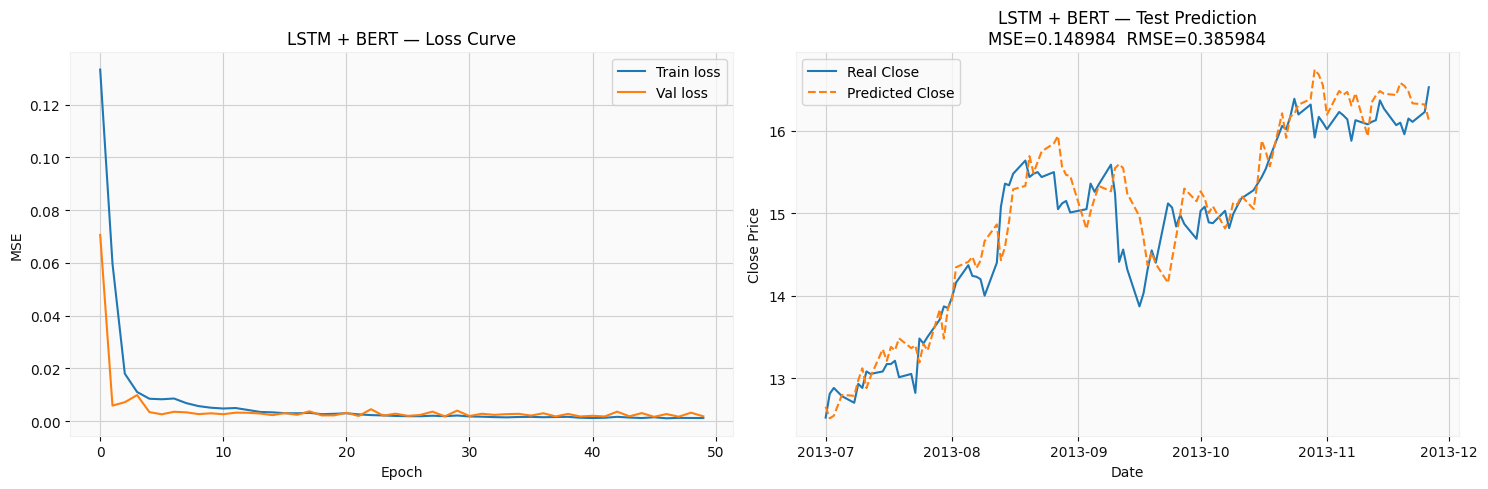

Test MSE  = 0.148984
Test RMSE = 0.385984


In [98]:
plot_results(
    train_losses = train_losses_bert,
    val_losses   = val_losses_bert,
    preds        = preds_bert,
    targets      = targets_bert,
    mse          = mse_bert,
    rmse         = rmse_bert,
    title        = 'LSTM + BERT'
)